# 02. Chunking, embedding and the vector index

**Goal.** Build the retrievable knowledge base and choose chunking settings with evidence.

**Playbook steps covered:** 3 (architecture: RAG first), 4 (indexing pipeline)

> Every step below has three parts: a **rationale** (why we do it), the **code** with line-level comments
> (how we do it), and an **evaluation** (how we know it worked). All notebooks run **offline** by default
> (hashing embedder + extractive baseline LLM). Switch to Claude and sentence-transformers with
> `AD_RAG_LLM_BACKEND=anthropic` and `AD_RAG_EMBEDDING_BACKEND=sentence-transformers`.

> The corpus is **synthetic educational content**. Nothing here is clinical guidance.

In [1]:
# ---- Setup: make the notebook runnable from anywhere (GitHub clone, Colab, Docker) ----
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the repo root by walking up until we see configs/config.yaml.
ROOT = Path.cwd()
while not (ROOT / "configs" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.environ["AD_RAG_HOME"] = str(ROOT)          # tell the package where the repo lives

# Fresh environment (e.g. Colab)? Install the package in editable mode first:
#   %pip install -q -e ".[notebooks]"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ad_rag import load_settings, build_pipeline

settings = load_settings()                     # typed config from configs/config.yaml (+ env overrides)
print("repo root :", ROOT)
print("embedder  :", settings.embedding.backend, "| llm backend:", settings.llm.backend)

repo root : /home/claude/alzheimers-llm-rag-agent
embedder  : hashing | llm backend: extractive


### Step 1: Chunk documents on structure, not on arbitrary character counts

**Rationale.** An embedding should represent ONE focused idea. We split on markdown headings first (so a chunk never straddles two topics), then pack paragraphs up to a size limit and carry a short overlap so an answer that straddles a boundary can still be retrieved. Each chunk keeps title and section, which are embedded as a contextual header and shown in citations.

**How this step is evaluated.** Inspect chunk size distribution and read a few chunks by eye. No chunk should be empty or wildly oversized.

sections: ['Introduction', 'Two-cutoff approach', 'Intermediate zone', 'Why two cutoffs', 'Reporting']
52 chunks | chars min/median/max = 67/181/388

--- embed_text of chunk 5 ---
 AI Assistant Use Policy | Incident handling
Suspected unsafe outputs are reported through the incident runbook within one business day and are recorded in the audit trail.


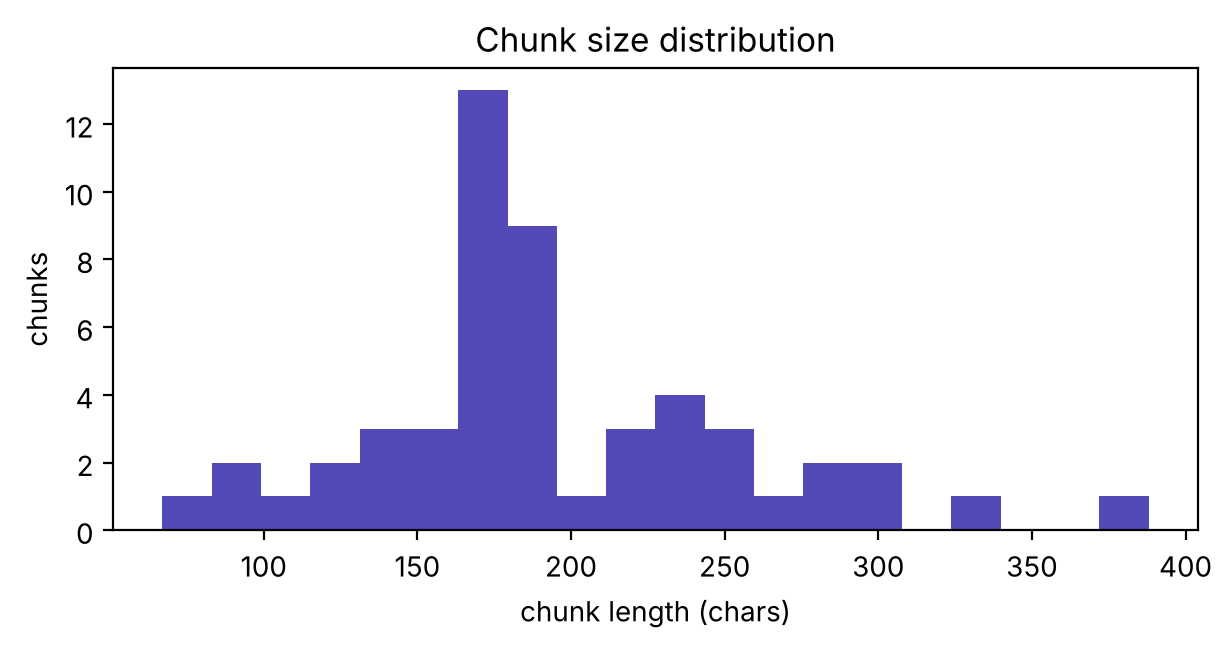

In [2]:
from ad_rag.ingestion import load_documents, corpus_version
from ad_rag.chunking import chunk_documents, split_sections

docs = load_documents(settings.path("corpus_dir"))

# Look at ONE document: how does it split into sections?
doc = next(d for d in docs if d.doc_id == "two_cutoff_interpretation")
print("sections:", [h for h, _ in split_sections(doc.text)])

# Chunk the whole corpus with the configured size/overlap.
chunks = chunk_documents(docs, settings.chunking.size_chars, settings.chunking.overlap_chars, corpus_version(docs))
lengths = pd.Series([len(c.text) for c in chunks])
print(f"{len(chunks)} chunks | chars min/median/max = {lengths.min()}/{int(lengths.median())}/{lengths.max()}")

# Read one chunk the way the embedder will see it (contextual header + body).
print("\n--- embed_text of chunk 5 ---\n", chunks[5].embed_text[:400])

plt.figure(figsize=(7, 3)); plt.hist(lengths, bins=20, color="#534AB7"); plt.xlabel("chunk length (chars)")
plt.ylabel("chunks"); plt.title("Chunk size distribution"); plt.show()
assert lengths.min() > 20, "found a near-empty chunk"

### Step 2: Choose the chunk size with a measured sweep

**Rationale.** Chunk size trades precision against context: tiny chunks lose meaning, huge chunks dilute the embedding and waste prompt budget. Instead of guessing, we rebuild the index for several sizes (in memory, `save=False`) and measure retrieval on the golden set.

**How this step is evaluated.** Three metrics on the in-scope golden questions: **hit@4** (expected source in top 4), **top-1** (expected source ranked first) and **MRR**. Top-1 and MRR are more discriminating than hit@4 on a small corpus.

,chunk_size,n_chunks,hit@4,top1,mrr
0,300,55,1.0,0.958,0.979
1,600,52,1.0,0.958,0.979
2,900,52,1.0,0.958,0.979
3,1500,52,1.0,0.958,0.979
4,2500,52,1.0,0.958,0.979


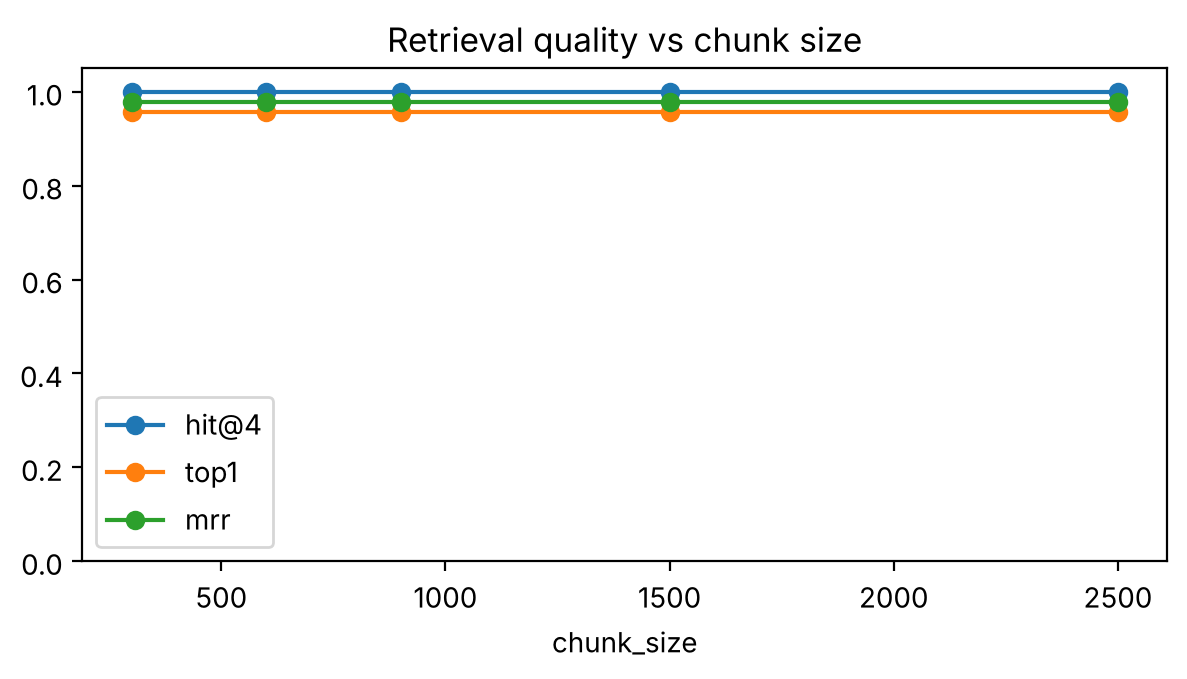

best by MRR: 300 chars | configured: 900


In [3]:
from ad_rag.indexing import build_index
from ad_rag.evaluation import load_golden

golden_in = [g for g in load_golden(ROOT / "data/eval/golden_set.jsonl") if g["category"] == "in_scope"]

def retrieval_quality(size, overlap_ratio=0.15, k=4):
    """Rebuild the index for one chunk size and score retrieval on the golden set."""
    s = settings.model_copy(deep=True)                  # copy: never mutate the real settings in an experiment
    s.chunking.size_chars = size
    s.chunking.overlap_chars = int(size * overlap_ratio)
    store, embedder, rep = build_index(s, save=False)    # save=False: experiment only, do not overwrite the index
    hit, top1, rr = [], [], []
    for g in golden_in:
        res = store.search(embedder.embed([g["question"]])[0], k)
        srcs = [r.chunk.source for r in res]
        exp = set(g["expected_sources"])
        hit.append(bool(exp & set(srcs)))               # was the right document anywhere in the top k?
        top1.append(srcs[0] in exp)                     # was it ranked first?
        rr.append(next((1 / (i + 1) for i, x in enumerate(srcs) if x in exp), 0.0))   # reciprocal rank
    return {"chunk_size": size, "n_chunks": rep.n_chunks, "hit@4": np.mean(hit), "top1": np.mean(top1), "mrr": np.mean(rr)}

sweep = pd.DataFrame([retrieval_quality(s) for s in [300, 600, 900, 1500, 2500]]).round(3)
display(sweep)

ax = sweep.plot(x="chunk_size", y=["hit@4", "top1", "mrr"], marker="o", figsize=(7, 3.2), ylim=(0, 1.05))
ax.set_title("Retrieval quality vs chunk size"); plt.show()
best = sweep.sort_values(["mrr", "top1"], ascending=False).iloc[0]
print("best by MRR:", int(best.chunk_size), "chars | configured:", settings.chunking.size_chars)

### Step 3: Embed: two interchangeable backends

**Rationale.** Both backends return L2-normalised vectors, so inner product equals cosine similarity. `hashing` is stateless and offline (CI, tests, demos). `sentence-transformers` gives dense semantic embeddings for production quality. Query and documents MUST use the same embedder or similarity is meaningless.

**How this step is evaluated.** Sanity checks: unit norm, determinism, and related text scoring higher than unrelated text.

In [4]:
from ad_rag.embeddings import get_embedder

embedder = get_embedder(settings.embedding)             # backend chosen by config / env var
print("embedder:", embedder.name, "| dimension:", embedder.dim)

# Related vs unrelated text: the first pair must be more similar than the second.
q, near, far = embedder.embed(["kidney disease raises biomarkers",
                               "chronic kidney disease and plasma biomarkers",
                               "best pizza toppings"])
print(f"similar pair  : {q @ near:.3f}\nunrelated pair: {q @ far:.3f}")
assert abs(np.linalg.norm(q) - 1) < 1e-4 and q @ near > q @ far

# Optional: dense embeddings (needs internet to download the model the first time).
if os.environ.get("USE_SENTENCE_TRANSFORMERS") == "1":
    from ad_rag.config import EmbeddingCfg
    st = get_embedder(EmbeddingCfg(backend="sentence-transformers"))
    print("sentence-transformers dim:", st.dim)
else:
    print("(set USE_SENTENCE_TRANSFORMERS=1 and `pip install -e .[st]` to try dense embeddings)")

embedder: hashing-4096 | dimension: 4096
similar pair  : 0.504
unrelated pair: 0.000
(set USE_SENTENCE_TRANSFORMERS=1 and `pip install -e .[st]` to try dense embeddings)


### Step 4: Build, persist and reload a versioned index

**Rationale.** Indexing is a batch job; serving is stateless. The only shared state is the index artifact on disk: vectors, chunk metadata and a manifest pinning the corpus version and embedder. Loading refuses to proceed if the embedder differs, preventing the classic silent failure of querying with a different model than was indexed.

**How this step is evaluated.** Round-trip equality (same chunks and vectors after reload) and a deliberate embedder-mismatch test that must raise.

In [5]:
from ad_rag.indexing import build_index
from ad_rag.vectorstore import VectorStore

store, embedder, report = build_index(settings, save=True)       # PHI gate -> chunk -> embed -> save
print(f"corpus version {report.corpus_version} | docs {report.n_docs_indexed}/{report.n_docs_loaded} | chunks {report.n_chunks}")
print("manifest:", json.dumps(VectorStore.read_manifest(settings.path("index_dir")), indent=2))

loaded = VectorStore.load(settings.path("index_dir"), expect_embedder=embedder.name)
assert len(loaded) == len(store) and np.allclose(loaded.vectors, store.vectors)

# The guard: loading with a different embedder name must fail loudly.
try:
    VectorStore.load(settings.path("index_dir"), expect_embedder="some-other-model")
except ValueError as e:
    print("\nmismatch correctly rejected:", str(e)[:90], "...")
else:
    raise AssertionError("embedder mismatch was not detected")

corpus version e639851bb748 | docs 10/10 | chunks 52
manifest: {
  "corpus_version": "e639851bb748",
  "embedder": "hashing-4096",
  "dim": 4096,
  "n_chunks": 52,
  "built_at": "2026-11-11T03:07:00Z",
  "faiss": true,
  "chunk_size": 900,
  "chunk_overlap": 150
}

mismatch correctly rejected: Index was built with embedder 'hashing-4096' but the service is configured for 'some-other ...


### Step 5: Inspect retrieval by eye

**Rationale.** Metrics hide failure modes. Reading the top results for a handful of questions (including a deliberately off-topic one) builds intuition for how the retriever behaves and where the refusal threshold should sit.

**How this step is evaluated.** Qualitative review: the expected document should rank first for in-scope questions; off-topic questions should score visibly lower.

In [6]:
pipe = build_pipeline(settings)

def show(question, k=3):
    print(f"\nQ: {question}")
    for r in pipe.retrieve(question, k):
        print(f"   {r.score:.3f}  {r.chunk.source}  |  {r.chunk.section}")

for q in ["Why do assays use two cutoffs instead of one?",
          "How does chronic kidney disease affect plasma biomarkers?",
          "What is the best pizza topping?"]:          # off-topic control
    show(q)


Q: Why do assays use two cutoffs instead of one?
   0.202  two_cutoff_interpretation.md  |  Why two cutoffs
   0.176  two_cutoff_interpretation.md  |  Two-cutoff approach
   0.161  assay_validation_summary.md  |  Performance

Q: How does chronic kidney disease affect plasma biomarkers?
   0.490  confounders_and_comorbidities.md  |  Chronic kidney disease
   0.334  blood_biomarker_overview.md  |  Limitations
   0.320  confounders_and_comorbidities.md  |  Body mass index

Q: What is the best pizza topping?
   0.060  disease_staging_and_definitions.md  |  Amyloid and tau
   0.000  ai_assistant_use_policy.md  |  Prohibited uses
   0.000  ai_assistant_use_policy.md  |  Purpose and scope


### Step 6: Visualise the embedding space

**Rationale.** A 2-D projection of the index is a quick health check: chunks from the same document or topic should cluster. Outliers can reveal mis-chunked or off-topic text.

**How this step is evaluated.** Visual only: clusters by document indicate the embedding captures topical structure.

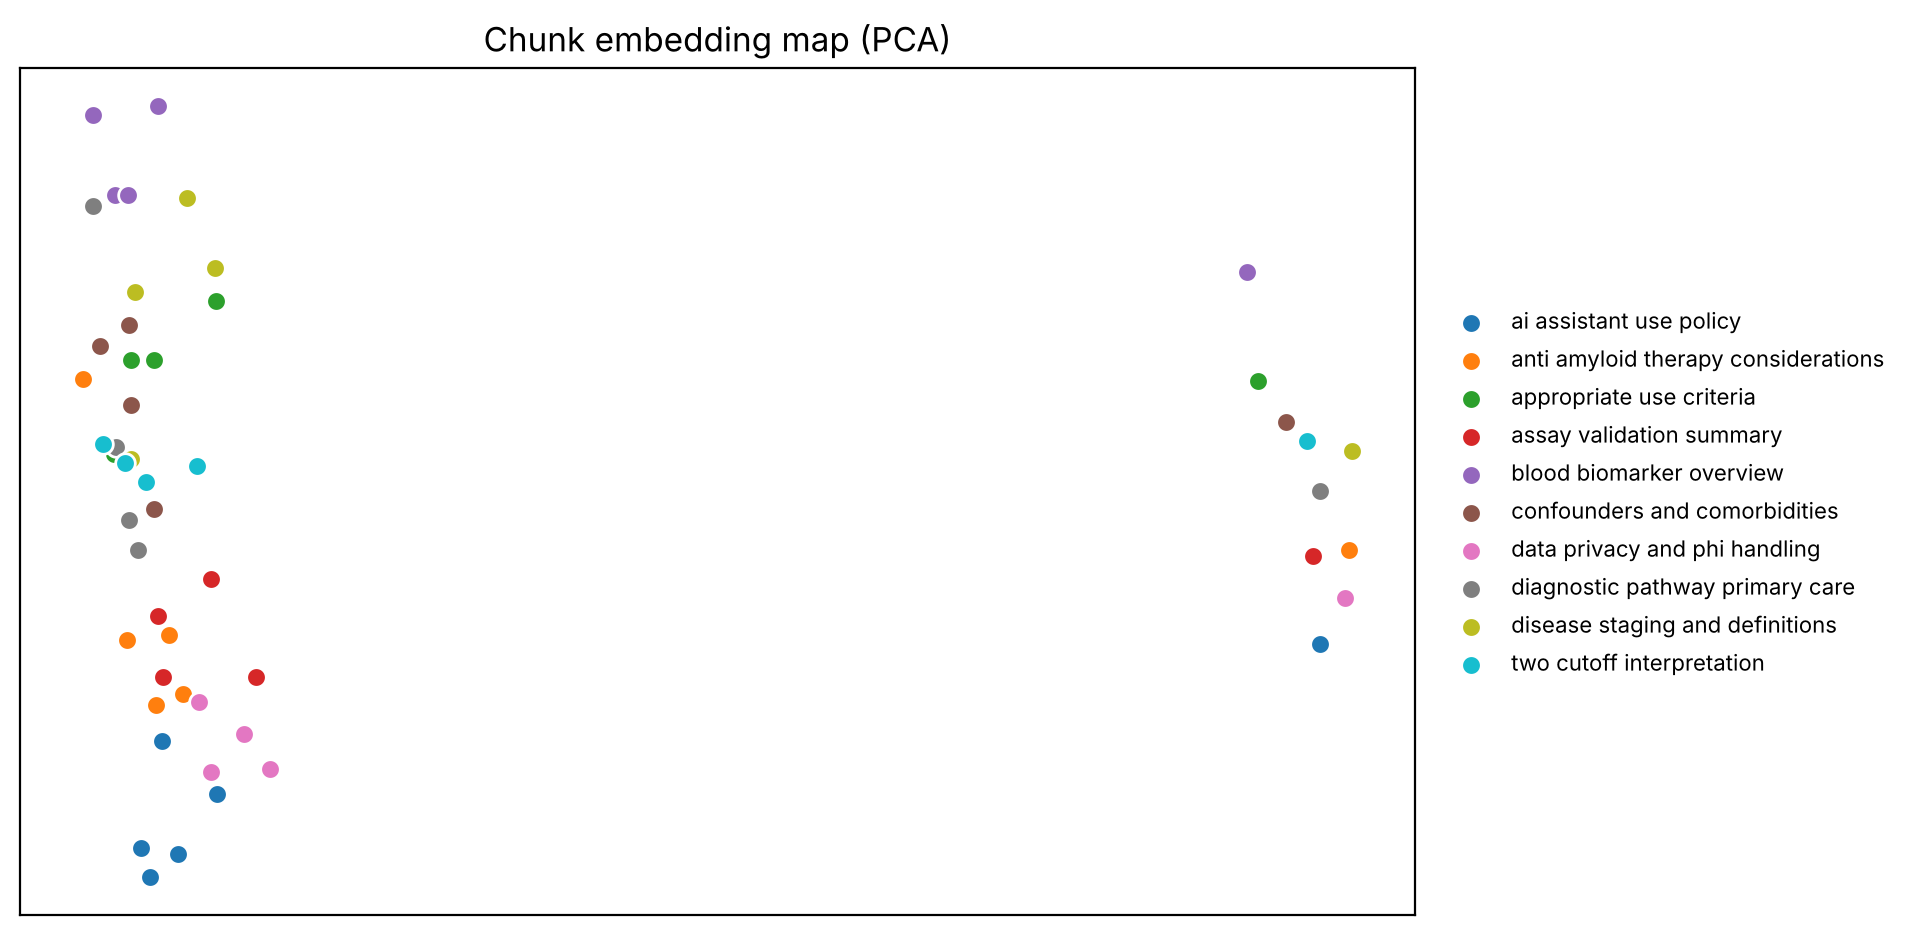

In [7]:
from sklearn.decomposition import PCA

Z = PCA(n_components=2, random_state=0).fit_transform(pipe.store.vectors)    # project vectors to 2D
doc_ids = sorted({c.doc_id for c in pipe.store.chunks})
cmap = plt.get_cmap("tab10")

plt.figure(figsize=(9, 5.5))
for i, d in enumerate(doc_ids):
    idx = [j for j, c in enumerate(pipe.store.chunks) if c.doc_id == d]
    plt.scatter(Z[idx, 0], Z[idx, 1], s=50, color=cmap(i % 10), label=d.replace("_", " "), edgecolor="white")
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
plt.title("Chunk embedding map (PCA)"); plt.xticks([]); plt.yticks([]); plt.show()

## Summary and exit criteria for this notebook

* Structure-aware chunking with contextual headers (Step 1).
* Chunk size chosen from a measured sweep, not a guess (Step 2). On a 10-document corpus most sizes saturate hit@4, so
  **prefer top-1 and MRR** and re-run this sweep when you replace the synthetic corpus with real documents.
* Versioned index with a hard guard against embedder mismatch (Step 4).

**Next:** `03_rag_generation_and_guardrails.ipynb` adds the LLM, guardrails and the refusal threshold.